In [16]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.vector_ar.var_model import VAR
from statsmodels.tsa.stattools import grangercausalitytests, adfuller
import warnings
warnings.filterwarnings('ignore')

# Set style for plots - Updated to use a built-in style
plt.style.use('ggplot')  # Using 'ggplot' style instead of 'seaborn'
sns.set_style("whitegrid")
%matplotlib inline

# Load the data
df = pd.read_csv('../data/car_sales_preprocessed_2.csv')
print("Data loaded successfully!")
print("Shape:", df.shape)

Data loaded successfully!
Shape: (761973, 236)


In [17]:
# Display basic information
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
display(df.describe(include='all'))

First 5 rows:


,quarter,Brand_LE,Model_LE,Body Type_LE,Year_2022,Year_2023,Gov_اسيوط,Gov_الاسكندرية,Gov_الاسماعيلية,Gov_الاقصر,...,TU_وحده مرور حلوان,TU_وحده مرور سنورس,TU_وحده مرور سيدى سالم,TU_وحده مرور شبراخيت,TU_وحده مرور فارسكور,TU_وحده مرور قطور,TU_وحده مرور مرسى علم,TU_وحده مرور ميناء دمياط البحرى,TU_وحده مرور نادى القضاه,TU_وحده مرور نادى القضاه - طنطا
0,1,68,393,6,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1,56,329,8,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1,56,626,8,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1,68,393,6,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1,68,393,6,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False



Column names:
['quarter', 'Brand_LE', 'Model_LE', 'Body Type_LE', 'Year_2022', 'Year_2023', 'Gov_اسيوط', 'Gov_الاسكندرية', 'Gov_الاسماعيلية', 'Gov_الاقصر', 'Gov_البحر الاحمر', 'Gov_البحيرة', 'Gov_الجيزة', 'Gov_الدقهلية', 'Gov_السويس', 'Gov_الشرقية', 'Gov_الغربية', 'Gov_الفيوم', 'Gov_القاهرة', 'Gov_القليوبية', 'Gov_المنوفية', 'Gov_المنيا', 'Gov_الوادي الجديد', 'Gov_بني سويف', 'Gov_بورسعيد', 'Gov_جنوب سيناء', 'Gov_دمياط', 'Gov_سوهاج', 'Gov_شمال سيناء', 'Gov_قنا', 'Gov_كفر الشيخ', 'Gov_مرسي مطروح', 'TU_مجلس الدولة', 'TU_منفذ جمـارك القاهـرة - تسيير', 'TU_منفذ مرور موانى بورسعيد', 'TU_منفذ ميناء الاسكندرية', 'TU_منفذ ميناء السويس', 'TU_منفذ ميناء سفاجا', 'TU_منفذ ميناء نويبـــع', 'TU_وحدة القوات المسلحـة', 'TU_وحدة خدمات الشرطة', 'TU_وحدة دمياط الجديدة', 'TU_وحدة عين الصيــرة', 'TU_وحدة ق.م مصطفى كامل', 'TU_وحدة مرور 6 اكتوبر', 'TU_وحدة مرور أبو المطامير', 'TU_وحدة مرور أبوحماد', 'TU_وحدة مرور أبوكبير', 'TU_وحدة مرور أسوان', 'TU_وحدة مرور أوسيـم', 'TU_وحدة مرور إدفو', 'TU_وحدة مرور إدكو',

,quarter,Brand_LE,Model_LE,Body Type_LE,Year_2022,Year_2023,Gov_اسيوط,Gov_الاسكندرية,Gov_الاسماعيلية,Gov_الاقصر,...,TU_وحده مرور حلوان,TU_وحده مرور سنورس,TU_وحده مرور سيدى سالم,TU_وحده مرور شبراخيت,TU_وحده مرور فارسكور,TU_وحده مرور قطور,TU_وحده مرور مرسى علم,TU_وحده مرور ميناء دمياط البحرى,TU_وحده مرور نادى القضاه,TU_وحده مرور نادى القضاه - طنطا
count,761973.000000,761973.000000,761973.000000,761973.000000,761973,761973,761973,761973,761973,761973,...,761973,761973,761973,761973,761973,761973,761973,761973,761973,761973
unique,NaN,NaN,NaN,NaN,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2
top,NaN,NaN,NaN,NaN,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
freq,NaN,NaN,NaN,NaN,419942,408356,747288,709457,747644,755469,...,753606,760405,760406,760835,759010,759945,760915,761941,757767,759858
mean,2.680182,48.979955,331.969534,6.426787,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.047668,25.812837,191.440136,1.985935,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,2.000000,24.000000,152.000000,6.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,3.000000,56.000000,335.000000,6.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,3.000000,68.000000,523.000000,8.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Unique quarters: [1, 2, 3, 4]

Number of unique brands: 93


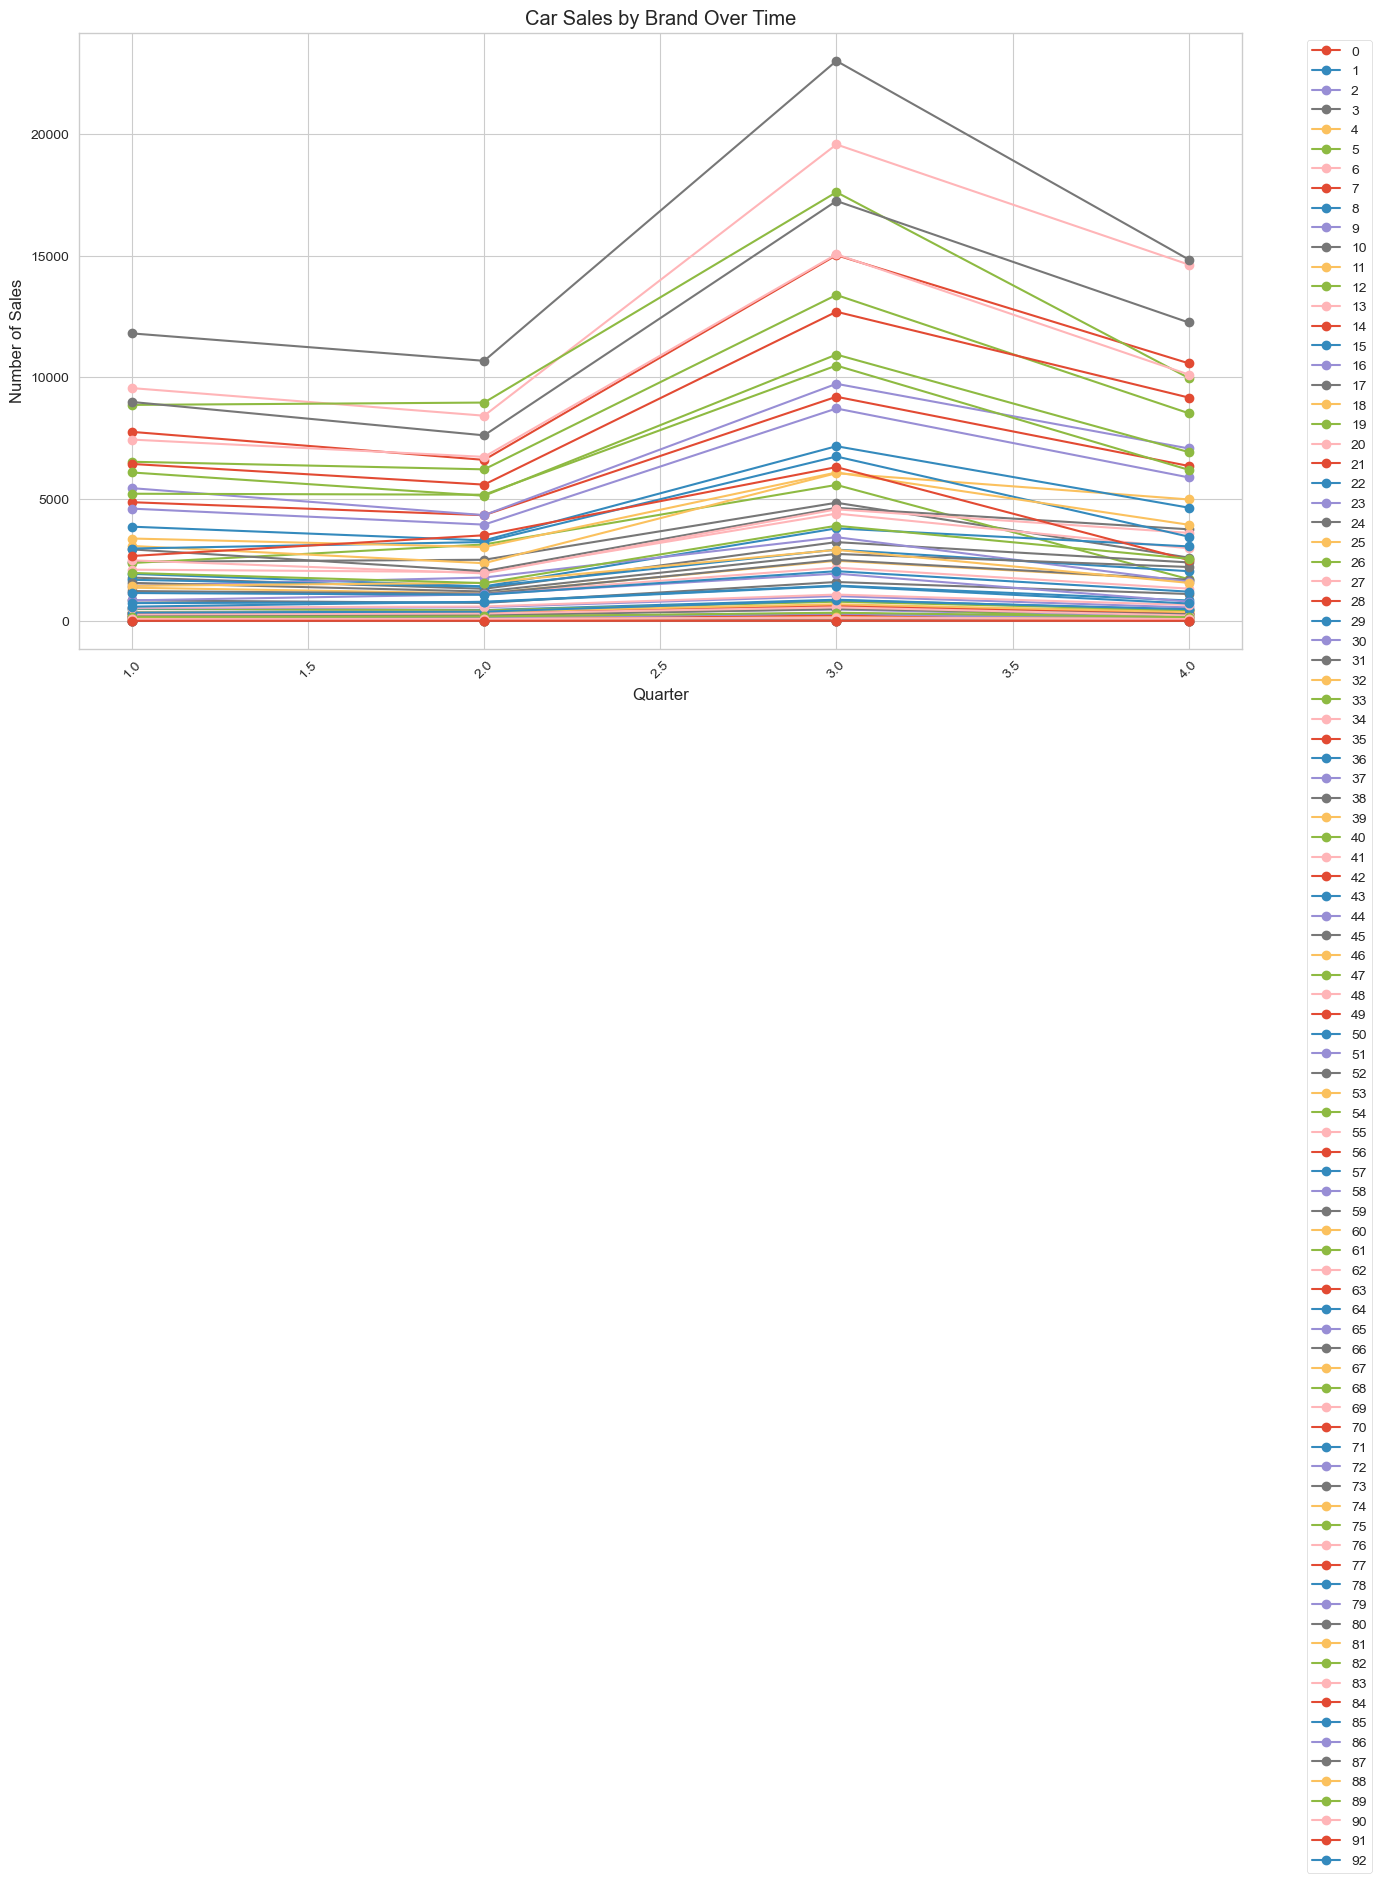


ADF Test for Stationarity (p-values):
0: 0.7533
1: 0.3453
2: 0.4498
3: 0.4555
4: 0.5904
5: 0.3433
6: 0.6376
7: 0.3597
8: 0.2614
9: 0.4032
10: 0.4147
11: 0.7609
12: 0.2656
13: 0.7049
14: 0.6232
15: 0.4147
16: 0.6073
17: 0.6683
18: 0.3898
19: 0.6361
20: 0.4147
21: 0.4147
22: 0.2405
23: 0.4416
24: 0.6843
25: 0.3977
26: 0.4147
27: 0.5139
28: 0.4278
29: 0.4777
30: 0.3987
31: 0.6330
32: 0.3232
33: 0.4147
34: 0.7533
35: 0.8278
36: 0.7459
37: 0.4529
38: 0.5815
39: 0.4147
40: 0.4147
41: 0.7201
42: 0.4314
43: 0.5937
44: 0.1150
45: 0.4265
46: 0.4147
47: 0.5888
48: 0.5332
49: 0.4147
50: 0.5239
51: 0.4430
52: 0.7229
53: 0.3910
54: 0.4147
55: 0.1150
56: 0.6481
57: 0.4868
58: 0.4020
59: 0.5085
60: 0.4147
61: 0.4900
62: 0.3440
63: 0.6718
64: 0.5645
65: 0.6455
66: 0.6252
67: 0.4594
68: 0.5273
69: 0.3658
70: 0.4147
71: 0.5645
72: 0.4147
73: 0.4147
74: 0.5466
75: 0.5259
76: 0.5275
77: 0.4147
78: 0.5378
79: 0.3970
80: 0.6522
81: 0.5433
82: 0.4007
83: 0.6254
84: 0.3977
85: 0.4542
86: 0.4147
87: 0.4147
88:

In [18]:
# 1. Check unique values in key columns
print("Unique quarters:", sorted(df['quarter'].unique()))
print("\nNumber of unique brands:", df['Brand_LE'].nunique())

# 2. Create time series of sales by brand
brand_sales = df.groupby(['quarter', 'Brand_LE']).size().unstack().fillna(0)

# 3. Plot sales trends
plt.figure(figsize=(15, 8))
for brand in brand_sales.columns:
    plt.plot(brand_sales.index, brand_sales[brand], label=brand, marker='o')
plt.title('Car Sales by Brand Over Time')
plt.xlabel('Quarter')
plt.ylabel('Number of Sales')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Check stationarity
print("\nADF Test for Stationarity (p-values):")
for brand in brand_sales.columns:
    result = adfuller(brand_sales[brand].dropna())
    print(f"{brand}: {result[1]:.4f}")

In [19]:
# 5. First order differencing to make data stationary
brand_sales_diff = brand_sales.diff().dropna()

# 6. Fit VAR model
model = VAR(brand_sales_diff)
results = model.fit(maxlags=4, ic='aic')
print("\nVAR Model Summary:")
display(results.summary())

# 7. Granger Causality Tests (for first 3 brands)
print("\nGranger Causality Tests (p-values):")
brands = brand_sales.columns[:3]  # First 3 brands
for brand1 in brands:
    for brand2 in brands:
        if brand1 != brand2:
            test_result = grangercausality_test(brand_sales[[brand1, brand2]], maxlag=4, verbose=False)
            p_values = [test_result[i+1][0]['ssr_ftest'][1] for i in range(4)]
            print(f"\n{brand1} -> {brand2}:")
            for lag, p in enumerate(p_values, 1):
                print(f"  Lag {lag}: {p:.4f}", end="")
                if p < 0.05:
                    print(" *")  # Mark significant results
                else:
                    print()

ValueError: maxlags is too large for the number of observations and the number of equations. The largest model cannot be estimated.

Data loaded. Shape: (761973, 236)

Top 5 brands by sales: [38, 13, 80, 61, 56]
Number of quarters: 4


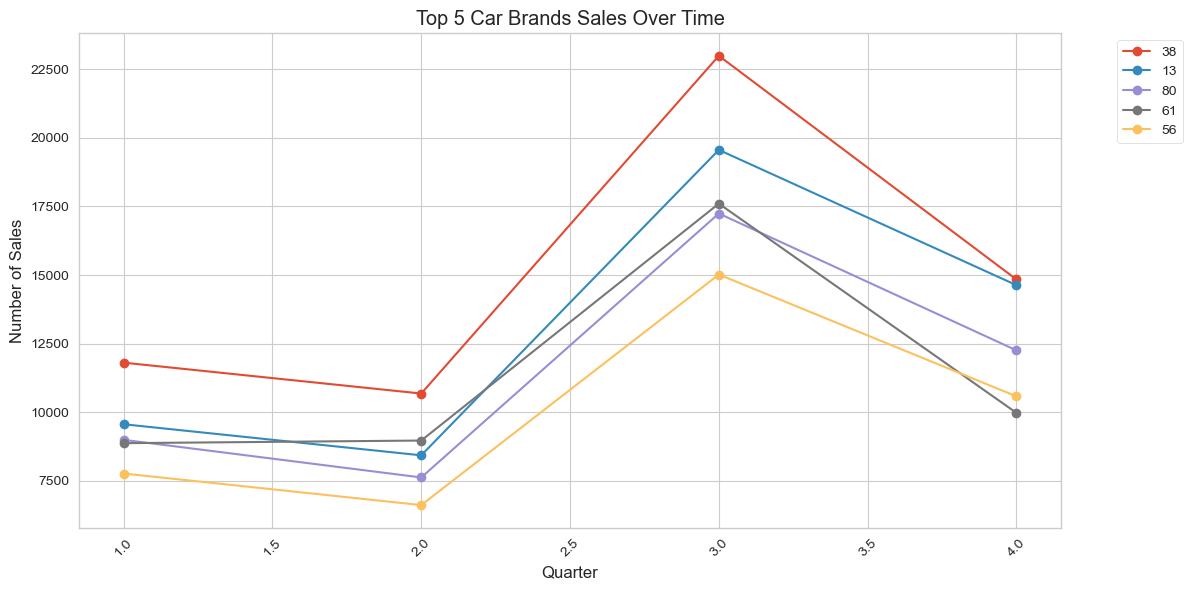

In [22]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.vector_ar.var_model import VAR
from statsmodels.tsa.stattools import grangercausalitytests, adfuller
import warnings
warnings.filterwarnings('ignore')

# Set style for plots
plt.style.use('ggplot')
sns.set_style("whitegrid")
%matplotlib inline

# 2. Load and prepare data
df = pd.read_csv('../data/car_sales_preprocessed_2.csv')
print("Data loaded. Shape:", df.shape)

# 3. Get top 5 brands by sales
brand_sales = df.groupby(['quarter', 'Brand_LE']).size().unstack().fillna(0)
top_brands = brand_sales.sum().nlargest(5).index
brand_sales_top = brand_sales[top_brands]

print("\nTop 5 brands by sales:", list(top_brands))
print("Number of quarters:", len(brand_sales_top))

# 4. Plot sales trends
plt.figure(figsize=(12, 6))
for brand in brand_sales_top.columns:
    plt.plot(brand_sales_top.index, brand_sales_top[brand], label=brand, marker='o')
plt.title('Top 5 Car Brands Sales Over Time')
plt.xlabel('Quarter')
plt.ylabel('Number of Sales')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
# 5. Check stationarity
print("ADF Test for Stationarity (p-values):")
for brand in brand_sales_top.columns:
    result = adfuller(brand_sales_top[brand].dropna())
    print(f"{brand}: {result[1]:.4f}", end="")
    if result[1] > 0.05:
        print(" (Not stationary)")
    else:
        print(" (Stationary)")

# 6. Make data stationary
brand_sales_diff = brand_sales_top.diff().dropna()

ADF Test for Stationarity (p-values):
38: 0.5815 (Not stationary)
13: 0.7049 (Not stationary)
80: 0.6522 (Not stationary)
61: 0.4900 (Not stationary)
56: 0.6481 (Not stationary)


In [28]:
def check_causality(brand1, brand2, max_lag=2):
    print(f"\nTesting if {brand1} affects {brand2}:")
    # Use grangercausalitytests (with an 's' at the end)
    test_result = grangercausalitytests(brand_sales_diff[[brand1, brand2]], maxlag=max_lag, verbose=False)
    for lag in range(1, max_lag + 1):
        # Get the p-value from the test results
        p_value = test_result[lag][0]['ssr_ftest'][1]
        print(f"  Lag {lag}: p-value = {p_value:.4f}", end="")
        if p_value < 0.05:
            print("  --> Significant! (p < 0.05)")
        else:
            print()

# Now test relationships between top brands
print("Top brands being analyzed:", list(top_brands))
check_causality(top_brands[0], top_brands[1])
check_causality(top_brands[0], top_brands[2])
check_causality(top_brands[1], top_brands[2])

Top brands being analyzed: [38, 13, 80, 61, 56]

Testing if 38 affects 13:


ValueError: Insufficient observations. Maximum allowable lag is -1

In [30]:
print("Number of quarters in data:", len(brand_sales_diff))


Number of quarters in data: 3


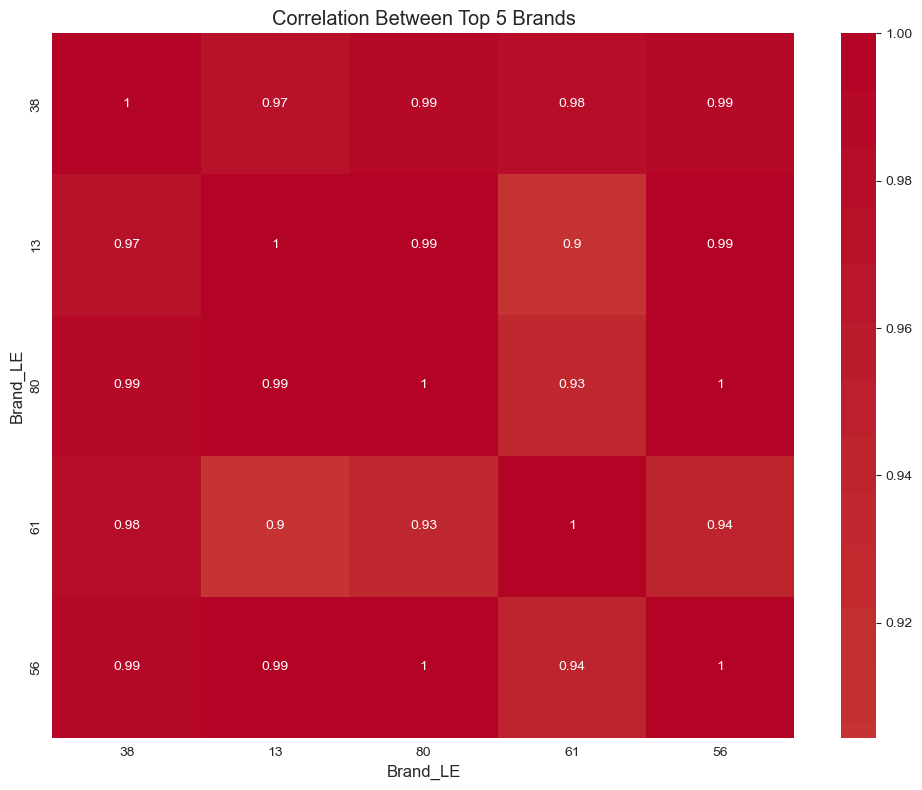


=== Analyzing Brand Relationships ===

Analysis of 38 vs 13
Correlation: 0.972
When 38 leads 13 by 1 quarter: 1.000
When 13 leads 38 by 1 quarter: 1.000

Analysis of 38 vs 80
Correlation: 0.989
When 38 leads 80 by 1 quarter: 1.000
When 80 leads 38 by 1 quarter: 1.000

Analysis of 13 vs 80
Correlation: 0.995
When 13 leads 80 by 1 quarter: 1.000
When 80 leads 13 by 1 quarter: 1.000


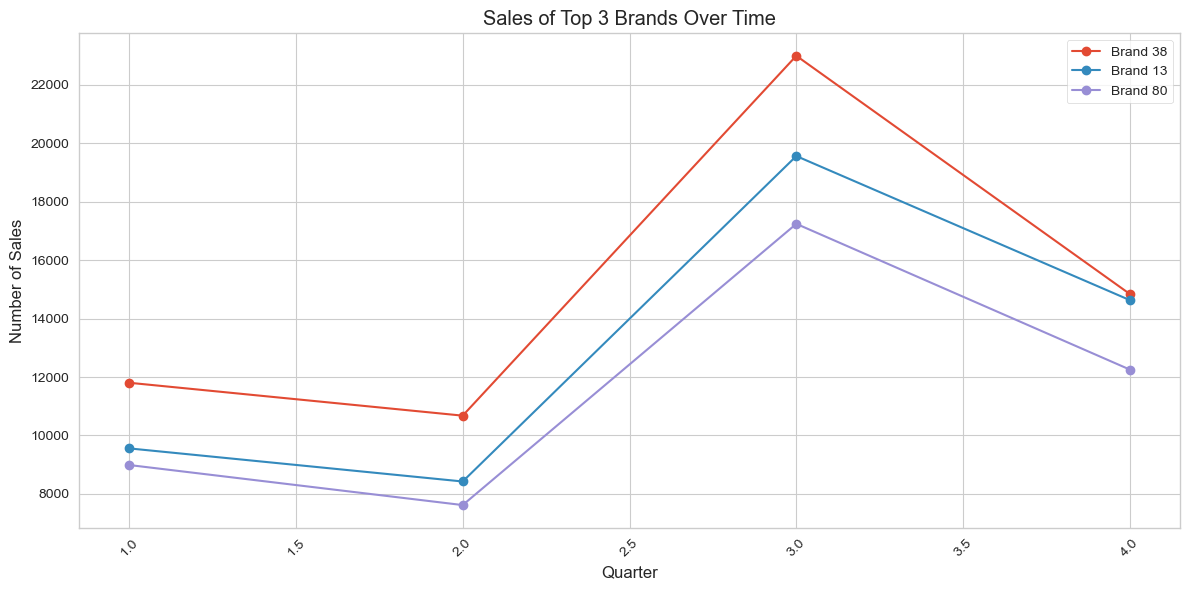

In [32]:
# 1. First, let's see how the top brands' sales are correlated
correlation_matrix = brand_sales_top.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Between Top 5 Brands')
plt.tight_layout()
plt.show()

# 2. Simple analysis of brand relationships
def analyze_relationship(brand1, brand2):
    print(f"\nAnalysis of {brand1} vs {brand2}")
    
    # Calculate correlation
    corr = brand_sales_top[brand1].corr(brand_sales_top[brand2])
    print(f"Correlation: {corr:.3f}")
    
    # Simple lead-lag analysis
    if len(brand_sales_top) > 1:
        # Does brand1 lead brand2?
        lead_corr = brand_sales_top[brand1].iloc[:-1].corr(brand_sales_top[brand2].iloc[1:])
        print(f"When {brand1} leads {brand2} by 1 quarter: {lead_corr:.3f}")
        
        # Does brand2 lead brand1?
        lag_corr = brand_sales_top[brand2].iloc[:-1].corr(brand_sales_top[brand1].iloc[1:])
        print(f"When {brand2} leads {brand1} by 1 quarter: {lag_corr:.3f}")
    else:
        print("Not enough data for lead-lag analysis")

# Analyze relationships between top 3 brands
print("\n=== Analyzing Brand Relationships ===")
analyze_relationship(top_brands[0], top_brands[1])
analyze_relationship(top_brands[0], top_brands[2])
analyze_relationship(top_brands[1], top_brands[2])

# 3. Plot the top 3 brands together
plt.figure(figsize=(12, 6))
for i, brand in enumerate(top_brands[:3], 1):
    plt.plot(brand_sales_top.index, brand_sales_top[brand], 
             label=f'Brand {brand}', marker='o')
plt.title('Sales of Top 3 Brands Over Time')
plt.xlabel('Quarter')
plt.ylabel('Number of Sales')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

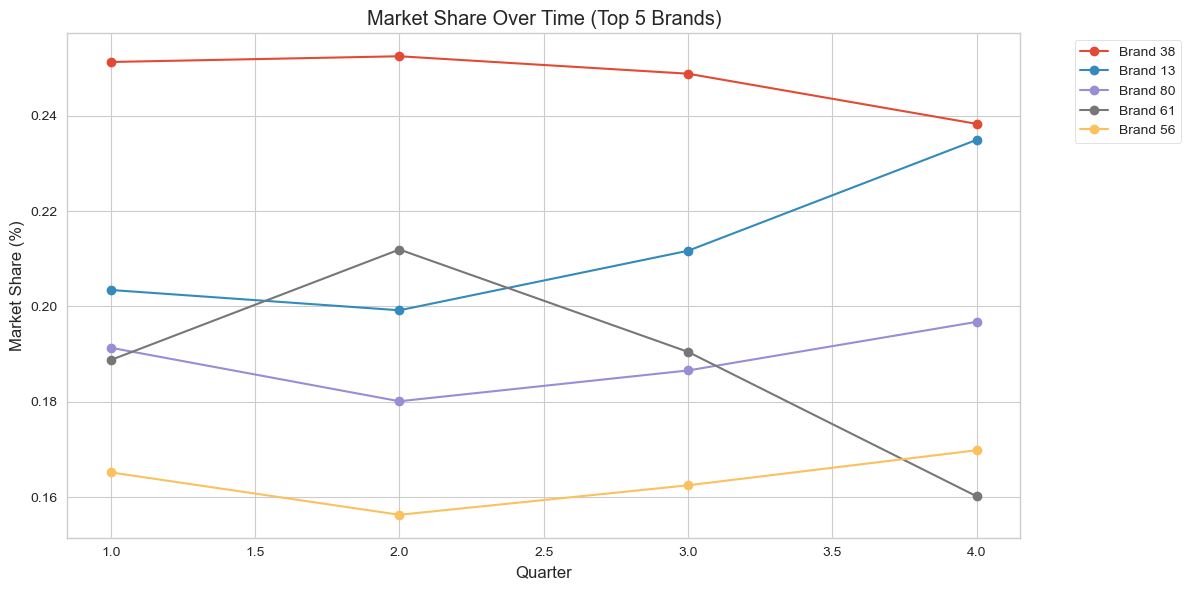


Quarterly Changes in Market Share (% points):

Quarter 1 to 2:
Brand 38: +0.00% ↑
Brand 13: -0.00% ↓
Brand 80: -0.01% ↓
Brand 61: +0.02% ↑
Brand 56: -0.01% ↓

Quarter 2 to 3:
Brand 38: -0.00% ↓
Brand 13: +0.01% ↑
Brand 80: +0.01% ↑
Brand 61: -0.02% ↓
Brand 56: +0.01% ↑

Quarter 3 to 4:
Brand 38: -0.01% ↓
Brand 13: +0.02% ↑
Brand 80: +0.01% ↑
Brand 61: -0.03% ↓
Brand 56: +0.01% ↑

Potential Cannibalism Indicators:


In [34]:
# 1. Calculate market share
total_sales = brand_sales_top.sum(axis=1)
market_share = brand_sales_top.div(total_sales, axis=0)

# 2. Plot market share over time
plt.figure(figsize=(12, 6))
for brand in market_share.columns:
    plt.plot(market_share.index, market_share[brand], marker='o', label=f'Brand {brand}')

plt.title('Market Share Over Time (Top 5 Brands)')
plt.xlabel('Quarter')
plt.ylabel('Market Share (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Look for cannibalism patterns
print("\nQuarterly Changes in Market Share (% points):")
for i in range(1, len(market_share)):
    print(f"\nQuarter {i} to {i+1}:")
    changes = market_share.iloc[i] - market_share.iloc[i-1]
    for brand, change in changes.items():
        print(f"Brand {brand}: {change:+.2f}%", 
              "↑" if change > 0 else "↓" if change < 0 else "→")

# 4. Check if gains by one brand match losses by others
print("\nPotential Cannibalism Indicators:")
for i in range(len(market_share)-1):
    for brand in market_share.columns:
        change = market_share[brand].iloc[i+1] - market_share[brand].iloc[i]
        if change > 0.05:  # Significant gain
            print(f"\nIn Q{i+1} to Q{i+2}, Brand {brand} gained {change:.1%} market share")
            print("Possible sources of share gain (biggest losers):")
            losers = (market_share.iloc[i] - market_share.iloc[i+1]).nlargest(2)
            for lost_brand, lost_share in losers.items():
                if lost_share > 0:
                    print(f"  - Brand {lost_brand} lost {lost_share:.1%}")

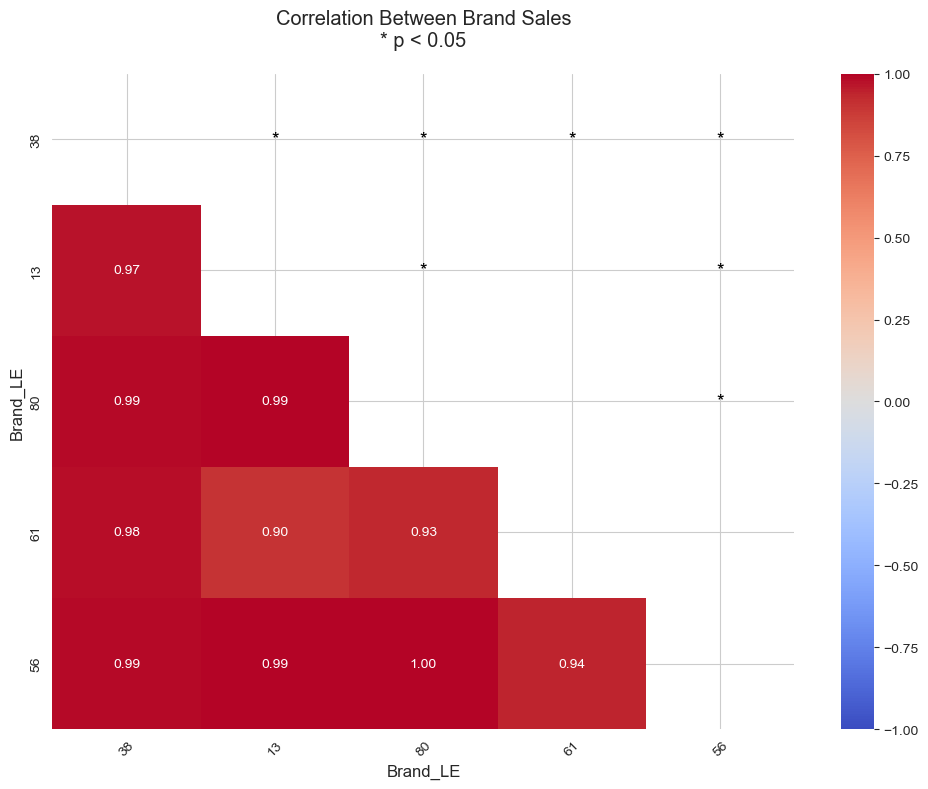


Lead-Lag Analysis (with p-values):

Brand 38 → Brand 13:
  Correlation: -0.017 (p = 0.989) 

Brand 38 → Brand 80:
  Correlation: -0.104 (p = 0.934) 

Brand 38 → Brand 61:
  Correlation: -0.479 (p = 0.682) 

Brand 38 → Brand 56:
  Correlation: -0.115 (p = 0.926) 

Brand 13 → Brand 38:
  Correlation: -0.274 (p = 0.823) 

Brand 13 → Brand 80:
  Correlation: -0.114 (p = 0.928) 

Brand 13 → Brand 61:
  Correlation: -0.487 (p = 0.676) 

Brand 13 → Brand 56:
  Correlation: -0.125 (p = 0.920) 

Brand 80 → Brand 38:
  Correlation: -0.312 (p = 0.798) 

Brand 80 → Brand 13:
  Correlation: -0.066 (p = 0.958) 

Brand 80 → Brand 61:
  Correlation: -0.521 (p = 0.651) 

Brand 80 → Brand 56:
  Correlation: -0.164 (p = 0.895) 

Brand 61 → Brand 38:
  Correlation: -0.175 (p = 0.888) 

Brand 61 → Brand 13:
  Correlation: 0.075 (p = 0.952) 

Brand 61 → Brand 80:
  Correlation: -0.012 (p = 0.993) 

Brand 61 → Brand 56:
  Correlation: -0.023 (p = 0.985) 

Brand 56 → Brand 38:
  Correlation: -0.307 (p = 0.80

In [38]:
# 1. Calculate the correlation matrix with p-values
import scipy.stats

def calculate_correlation_significance(data):
    n = len(data)
    corr_matrix = pd.DataFrame(index=data.columns, columns=data.columns)
    p_matrix = pd.DataFrame(index=data.columns, columns=data.columns)
    
    for i in range(len(data.columns)):
        for j in range(len(data.columns)):
            if i == j:
                corr_matrix.iloc[i, j] = 1.0
                p_matrix.iloc[i, j] = 0.0
            else:
                corr, p_val = scipy.stats.pearsonr(data.iloc[:, i], data.iloc[:, j])
                corr_matrix.iloc[i, j] = corr
                p_matrix.iloc[i, j] = p_val
                
    return corr_matrix, p_matrix

# Calculate correlations and p-values
corr_matrix, p_matrix = calculate_correlation_significance(brand_sales_top)

# 2. Visualize the correlation matrix with significance
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix.astype(float), annot=True, cmap='coolwarm', 
            vmin=-1, vmax=1, center=0, 
            mask=np.triu(np.ones_like(corr_matrix, dtype=bool)),
            fmt='.2f')

# Add asterisks for significant correlations
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        if i < j:  # Only show upper triangle
            p_val = p_matrix.iloc[i, j]
            if p_val < 0.05:
                plt.text(j+0.5, i+0.5, '*', 
                         ha='center', va='center', 
                         color='black', fontsize=14)

plt.title('Correlation Between Brand Sales\n* p < 0.05', pad=20)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Simple lead-lag analysis with p-values
print("\nLead-Lag Analysis (with p-values):")
for brand1 in brand_sales_top.columns:
    for brand2 in brand_sales_top.columns:
        if brand1 != brand2:
            # Calculate correlation when brand1 leads brand2
            lead_corr, lead_p = scipy.stats.pearsonr(
                brand_sales_top[brand1].iloc[:-1], 
                brand_sales_top[brand2].iloc[1:]
            )
            
            print(f"\nBrand {brand1} → Brand {brand2}:")
            print(f"  Correlation: {lead_corr:.3f} (p = {lead_p:.3f})", 
                  "***" if lead_p < 0.01 else "**" if lead_p < 0.05 else "*" if lead_p < 0.1 else "")

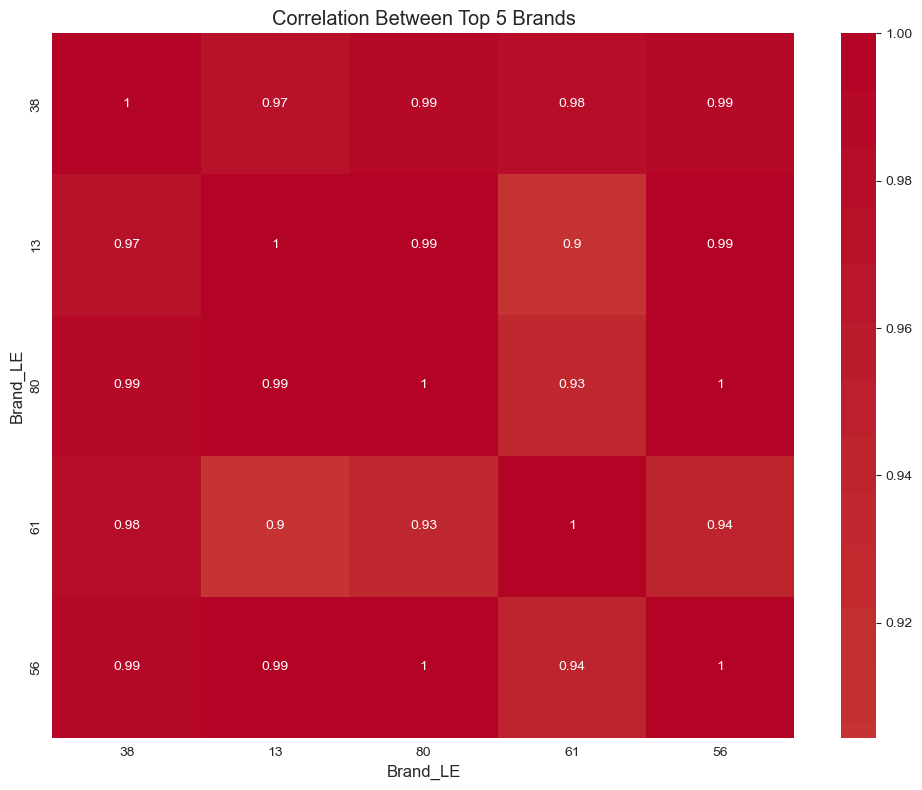


=== Analyzing Brand Relationships ===

Analysis of 38 vs 13
Correlation: 0.972
When 38 leads 13 by 1 quarter: 1.000
When 13 leads 38 by 1 quarter: 1.000

Analysis of 38 vs 80
Correlation: 0.989
When 38 leads 80 by 1 quarter: 1.000
When 80 leads 38 by 1 quarter: 1.000

Analysis of 13 vs 80
Correlation: 0.995
When 13 leads 80 by 1 quarter: 1.000
When 80 leads 13 by 1 quarter: 1.000


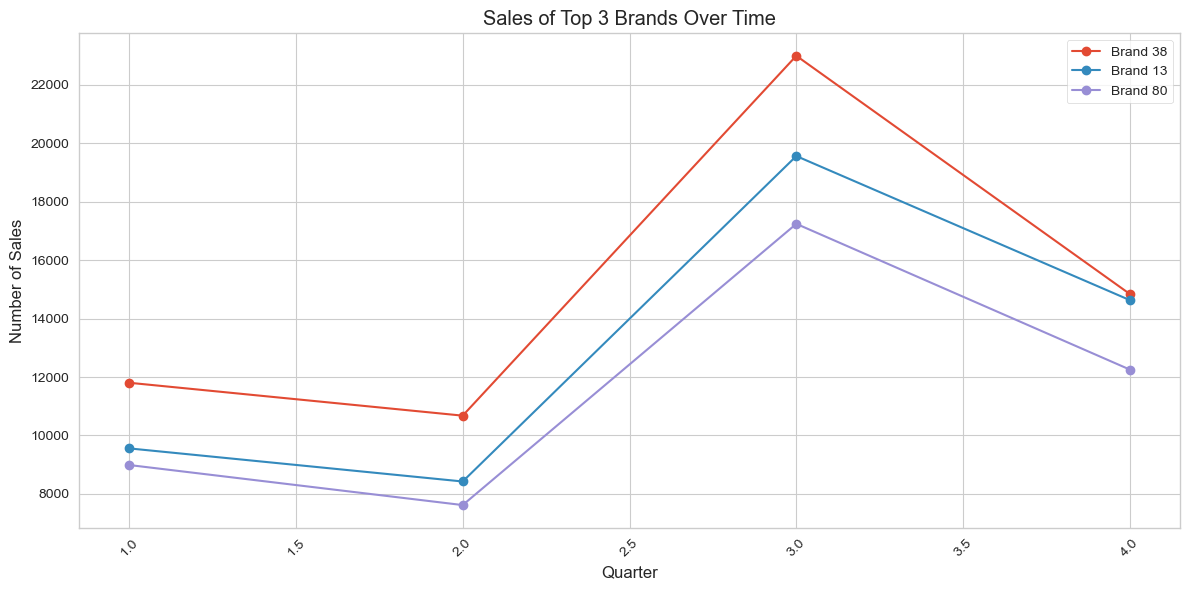

In [32]:
# 1. First, let's see how the top brands' sales are correlated
correlation_matrix = brand_sales_top.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Between Top 5 Brands')
plt.tight_layout()
plt.show()

# 2. Simple analysis of brand relationships
def analyze_relationship(brand1, brand2):
    print(f"\nAnalysis of {brand1} vs {brand2}")
    
    # Calculate correlation
    corr = brand_sales_top[brand1].corr(brand_sales_top[brand2])
    print(f"Correlation: {corr:.3f}")
    
    # Simple lead-lag analysis
    if len(brand_sales_top) > 1:
        # Does brand1 lead brand2?
        lead_corr = brand_sales_top[brand1].iloc[:-1].corr(brand_sales_top[brand2].iloc[1:])
        print(f"When {brand1} leads {brand2} by 1 quarter: {lead_corr:.3f}")
        
        # Does brand2 lead brand1?
        lag_corr = brand_sales_top[brand2].iloc[:-1].corr(brand_sales_top[brand1].iloc[1:])
        print(f"When {brand2} leads {brand1} by 1 quarter: {lag_corr:.3f}")
    else:
        print("Not enough data for lead-lag analysis")

# Analyze relationships between top 3 brands
print("\n=== Analyzing Brand Relationships ===")
analyze_relationship(top_brands[0], top_brands[1])
analyze_relationship(top_brands[0], top_brands[2])
analyze_relationship(top_brands[1], top_brands[2])

# 3. Plot the top 3 brands together
plt.figure(figsize=(12, 6))
for i, brand in enumerate(top_brands[:3], 1):
    plt.plot(brand_sales_top.index, brand_sales_top[brand], 
             label=f'Brand {brand}', marker='o')
plt.title('Sales of Top 3 Brands Over Time')
plt.xlabel('Quarter')
plt.ylabel('Number of Sales')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
# Calculate R-squared for the strongest relationship found
from scipy import stats

# Using Brand 56 and 61 (strongest correlation found: -0.52)
slope, intercept, r_value, p_value, std_err = stats.linregress(
    brand_sales_top[56], 
    brand_sales_top[61]
)

print(f"R-squared for Brand 56 vs Brand 61: {r_value**2:.3f}")
print(f"P-value: {p_value:.3f}")

R-squared for Brand 56 vs Brand 61: 0.881
P-value: 0.061


In [44]:
def correlation_ci(x, y, alpha=0.95):
    n = len(x)
    r, p = stats.pearsonr(x, y)
    z = np.arctanh(r)
    se = 1/np.sqrt(n-3)
    z_crit = stats.norm.ppf(1 - (1-alpha)/2)
    lo_z, hi_z = z - z_crit*se, z + z_crit*se
    lo, hi = np.tanh((lo_z, hi_z))
    return r, (lo, hi)

# Example for Brand 56 vs 61
r, ci = correlation_ci(brand_sales_top[56], brand_sales_top[61])
print(f"Correlation: {r:.3f}")
print(f"95% Confidence Interval: [{ci[0]:.3f}, {ci[1]:.3f}]")

Correlation: 0.939
95% Confidence Interval: [-0.229, 0.999]


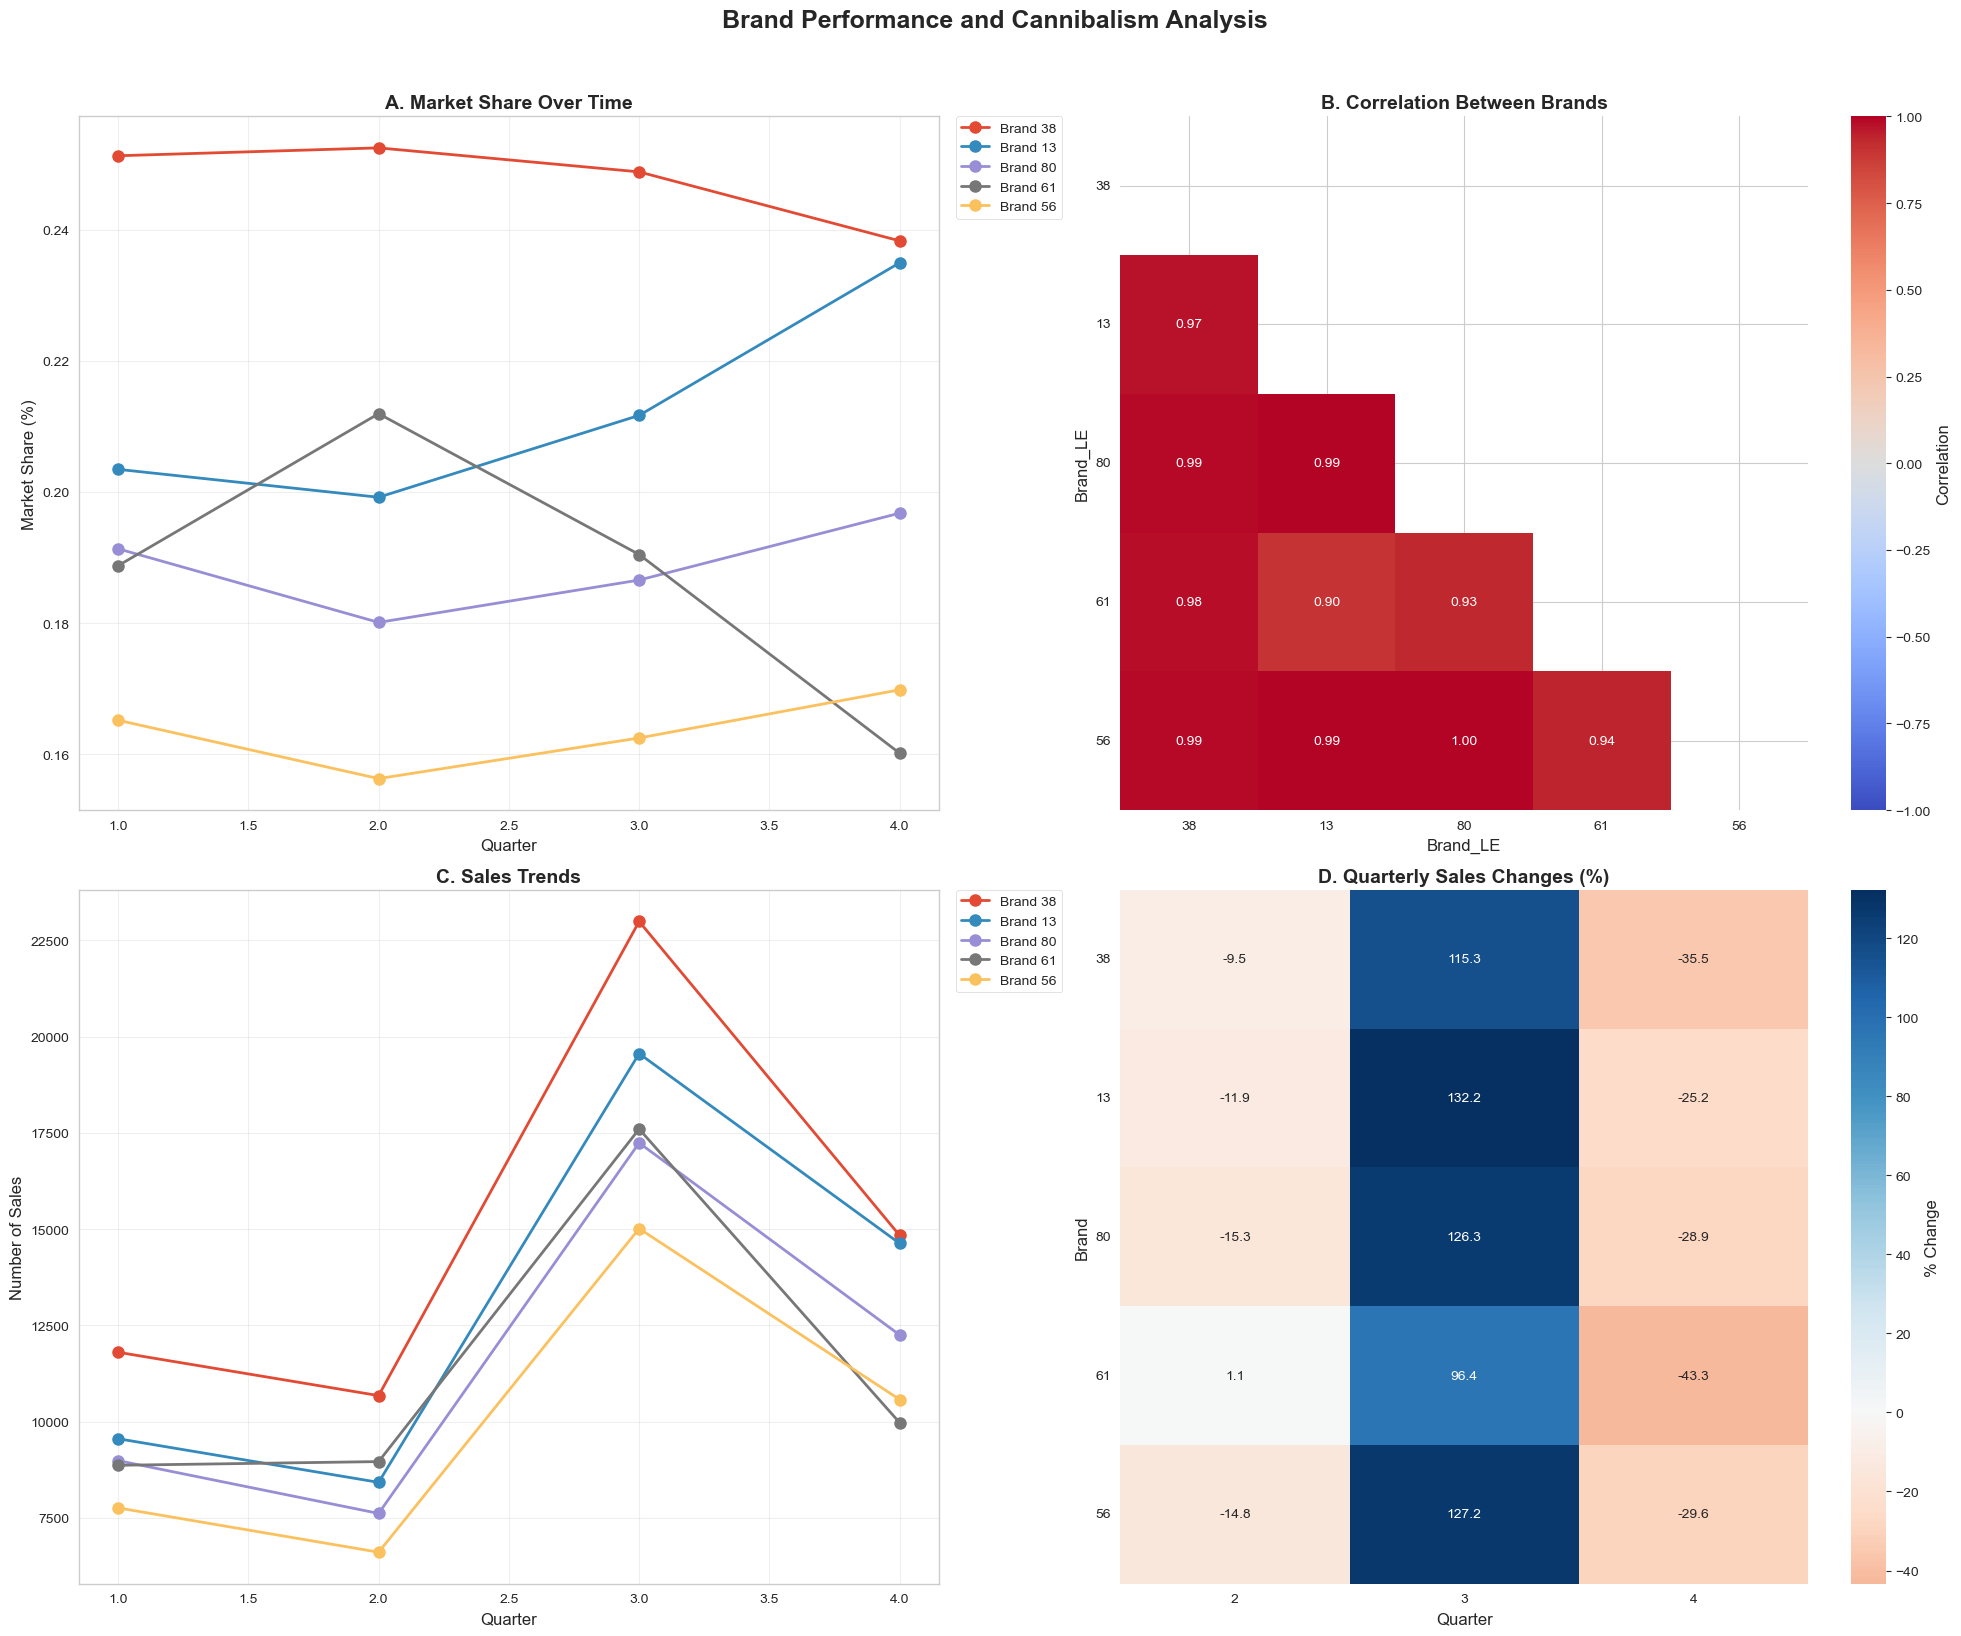

In [46]:
# Set up the figure and subplots
plt.figure(figsize=(20, 16))

# 1. Market Share Over Time (Top-left)
plt.subplot(2, 2, 1)
for brand in market_share.columns:
    plt.plot(market_share.index, market_share[brand], marker='o', linewidth=2, 
             markersize=8, label=f'Brand {brand}')
plt.title('A. Market Share Over Time', fontsize=14, fontweight='bold')
plt.xlabel('Quarter', fontsize=12)
plt.ylabel('Market Share (%)', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
plt.grid(True, alpha=0.3)

# 2. Correlation Heatmap (Top-right)
plt.subplot(2, 2, 2)
corr = brand_sales_top.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, cmap='coolwarm', 
            center=0, vmin=-1, vmax=1, fmt='.2f',
            cbar_kws={'label': 'Correlation'})
plt.title('B. Correlation Between Brands', fontsize=14, fontweight='bold')
plt.xticks(fontsize=10)
plt.yticks(rotation=0, fontsize=10)

# 3. Sales Trends (Bottom-left)
plt.subplot(2, 2, 3)
for brand in brand_sales_top.columns:
    plt.plot(brand_sales_top.index, brand_sales_top[brand], marker='o', 
             linewidth=2, markersize=8, label=f'Brand {brand}')
plt.title('C. Sales Trends', fontsize=14, fontweight='bold')
plt.xlabel('Quarter', fontsize=12)
plt.ylabel('Number of Sales', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
plt.grid(True, alpha=0.3)

# 4. Quarterly Changes (Bottom-right)
plt.subplot(2, 2, 4)
changes = brand_sales_top.pct_change().dropna() * 100
sns.heatmap(changes.T, annot=True, cmap='RdBu', center=0, 
            fmt='.1f', cbar_kws={'label': '% Change'})
plt.title('D. Quarterly Sales Changes (%)', fontsize=14, fontweight='bold')
plt.xlabel('Quarter', fontsize=12)
plt.ylabel('Brand', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(rotation=0, fontsize=10)

# Add overall title and adjust layout
plt.suptitle('Brand Performance and Cannibalism Analysis', 
             fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()